# Housing Price Prediction - Samsung Innovation Campus AI Assignment

In this assignment, we analyze the `Housing.csv` dataset and build machine learning regression models to predict property sales prices. The notebook is structured into five core sections:
1. **Data Analysis**: Loading the dataset, inspecting data types, missing values, duplicates, summary statistics, skewness, and IQR outliers.
2. **Data Extraction & Preprocessing**: Encoding binary indicators, one-hot encoding categorical variables, 80/20 train-test splitting, and feature scaling with `StandardScaler`.
3. **Exploratory Data Analysis (EDA)**: Price distribution, area vs. price by air conditioning, price by furnishing status, and feature correlation heatmap.
4. **Model Creation**: Training Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting, and Log-Linear Regression.
5. **Model Evaluation**: Metrics comparison table (MAE, RMSE, Test R2, 5-Fold CV R2), residual analysis plots, linear regression feature coefficient inspection, and final conclusions.

## 1. Data Analysis

We load `Housing.csv` and inspect its shape, structure, data types, missing values, and duplicates.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

# Set visualization aesthetics
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

df = pd.read_csv('Housing.csv')
print(f'Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()

Dataset Shape: 545 rows, 13 columns


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


Next, we check column data types, non-null counts, and verify whether duplicate rows exist.

In [2]:
print('--- Dataset Info ---')
df.info()

print('\n--- Missing Values Count ---')
print(df.isnull().sum())

print(f'\nTotal Duplicate Rows: {df.duplicated().sum()}')

--- Dataset Info ---
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB

--- Missing Values Count ---
price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
g

There are no missing values or duplicate records in the dataset. Now we examine the summary statistics for numeric columns and value counts for all categorical features.

In [3]:
print('--- Numerical Summary Statistics ---')
display(df.describe().T)

categorical_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea', 'furnishingstatus']
print('\n--- Categorical Variable Value Counts ---')
for col in categorical_cols:
    print(f'\n{col}:')
    print(df[col].value_counts())

--- Numerical Summary Statistics ---


,count,mean,std,min,25%,50%,75%,max
price,545.0,4.766729e+06,1.870440e+06,1750000.0,3430000.0,4340000.0,5740000.0,13300000.0
area,545.0,5.150541e+03,2.170141e+03,1650.0,3600.0,4600.0,6360.0,16200.0
bedrooms,545.0,2.965138e+00,7.380639e-01,1.0,2.0,3.0,3.0,6.0
bathrooms,545.0,1.286239e+00,5.024696e-01,1.0,1.0,1.0,2.0,4.0
stories,545.0,1.805505e+00,8.674925e-01,1.0,1.0,2.0,2.0,4.0
parking,545.0,6.935780e-01,8.615858e-01,0.0,0.0,0.0,1.0,3.0



--- Categorical Variable Value Counts ---

mainroad:
mainroad
yes    468
no      77
Name: count, dtype: int64

guestroom:
guestroom
no     448
yes     97
Name: count, dtype: int64

basement:
basement
no     354
yes    191
Name: count, dtype: int64

hotwaterheating:
hotwaterheating
no     520
yes     25
Name: count, dtype: int64

airconditioning:
airconditioning
no     373
yes    172
Name: count, dtype: int64

prefarea:
prefarea
no     417
yes    128
Name: count, dtype: int64

furnishingstatus:
furnishingstatus
semi-furnished    227
unfurnished       178
furnished         140
Name: count, dtype: int64


We now compute the skewness of `price` and `area`, and identify potential outliers using the 1.5 * IQR rule.

In [4]:
print('--- Skewness ---')
print(f"Price skewness: {df['price'].skew():.4f}")
print(f"Area skewness:  {df['area'].skew():.4f}")

print('\n--- IQR Outlier Detection ---')
for col in ['price', 'area']:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    pct = (len(outliers) / len(df)) * 100
    print(f'Feature: {col}')
    print(f'  Q1: {q1:,.0f}, Q3: {q3:,.0f}, IQR: {iqr:,.0f}')
    print(f'  Normal Range: [{lower_bound:,.0f}, {upper_bound:,.0f}]')
    print(f'  Outliers: {len(outliers)} ({pct:.2f}%)\n')

--- Skewness ---
Price skewness: 1.2122
Area skewness:  1.3212

--- IQR Outlier Detection ---
Feature: price
  Q1: 3,430,000, Q3: 5,740,000, IQR: 2,310,000
  Normal Range: [-35,000, 9,205,000]
  Outliers: 15 (2.75%)

Feature: area
  Q1: 3,600, Q3: 6,360, IQR: 2,760
  Normal Range: [-540, 10,500]
  Outliers: 12 (2.20%)



Data Analysis observations:
- The dataset contains 545 rows and 13 columns with zero missing values and zero duplicate rows.
- Both `price` (skewness = 1.21) and `area` (skewness = 1.32) exhibit positive right-skewness.
- Using the 1.5 * IQR threshold, we detect 15 outliers in `price` (2.75%) and 12 in `area` (2.20%). These correspond to legitimate high-value properties in prime locations rather than measurement errors, so we retain them for model training.

## 2. Data Extraction & Preprocessing

In this section, we prepare the data for regression modeling:
1. Map binary yes/no columns (`mainroad`, `guestroom`, `basement`, `hotwaterheating`, `airconditioning`, `prefarea`) to integer values 1 and 0.
2. One-hot encode `furnishingstatus` with `drop_first=True` to prevent multicollinearity (dummy variable trap).
3. Separate features `X` and target `y` (`price`).
4. Split the data into 80% training and 20% testing sets using `random_state=42`.
5. Standardize numeric features (`area`, `bedrooms`, `bathrooms`, `stories`, `parking`) with `StandardScaler`, fitting only on the training set to prevent data leakage.

In [5]:
# Map binary yes/no columns to 1/0
binary_cols = ['mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'prefarea']
df_clean = df.copy()
for col in binary_cols:
    df_clean[col] = df_clean[col].map({'yes': 1, 'no': 0})

# One-hot encode furnishingstatus dropping the first level ('furnished')
df_clean = pd.get_dummies(df_clean, columns=['furnishingstatus'], drop_first=True, dtype=int)

# Separate features X and target y
X = df_clean.drop('price', axis=1)
y = df_clean['price']

# 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize numerical features using parameters fit strictly on X_train
num_cols = ['area', 'bedrooms', 'bathrooms', 'stories', 'parking']
scaler = StandardScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(f'X_train shape: {X_train_scaled.shape}')
print(f'X_test shape:  {X_test_scaled.shape}')
X_train_scaled.head()

X_train shape: (436, 13)
X_test shape:  (109, 13)


,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
46,0.384168,0.055271,1.539173,2.587644,1,0,0,0,1,0.367957,0,0,0
93,0.929181,0.055271,1.539173,-0.912499,1,0,1,0,1,2.709987,0,1,0
335,-0.607755,-1.283514,-0.557950,-0.912499,1,0,1,0,1,1.538972,0,0,0
412,-1.155492,0.055271,-0.557950,0.254215,1,0,1,0,0,-0.803059,1,0,1
471,-0.637730,0.055271,-0.557950,0.254215,1,0,0,0,0,-0.803059,0,0,1


Data extraction and preprocessing is complete. The encoded feature matrix consists of 13 numeric predictors. The training set contains 436 records and the testing set contains 109 records.

## 3. Exploratory Data Analysis (EDA)

We explore feature relationships and target dynamics with a 4-panel visual dashboard:
1. **Price Distribution**: Histogram and KDE showing the distribution of property prices.
2. **Area vs. Price by Air Conditioning**: Scatter plot illustrating price scaling with area and the AC price premium.
3. **Price by Furnishing Status**: Boxplot comparing price spreads across furnished, semi-furnished, and unfurnished properties.
4. **Feature Correlation Bar Chart**: Pearson correlation coefficients of all features with `price`.

The resulting visualization is saved to `figures/eda_summary.png`.

C:\Users\rajak\AppData\Local\Temp\ipykernel_8744\3951938354.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


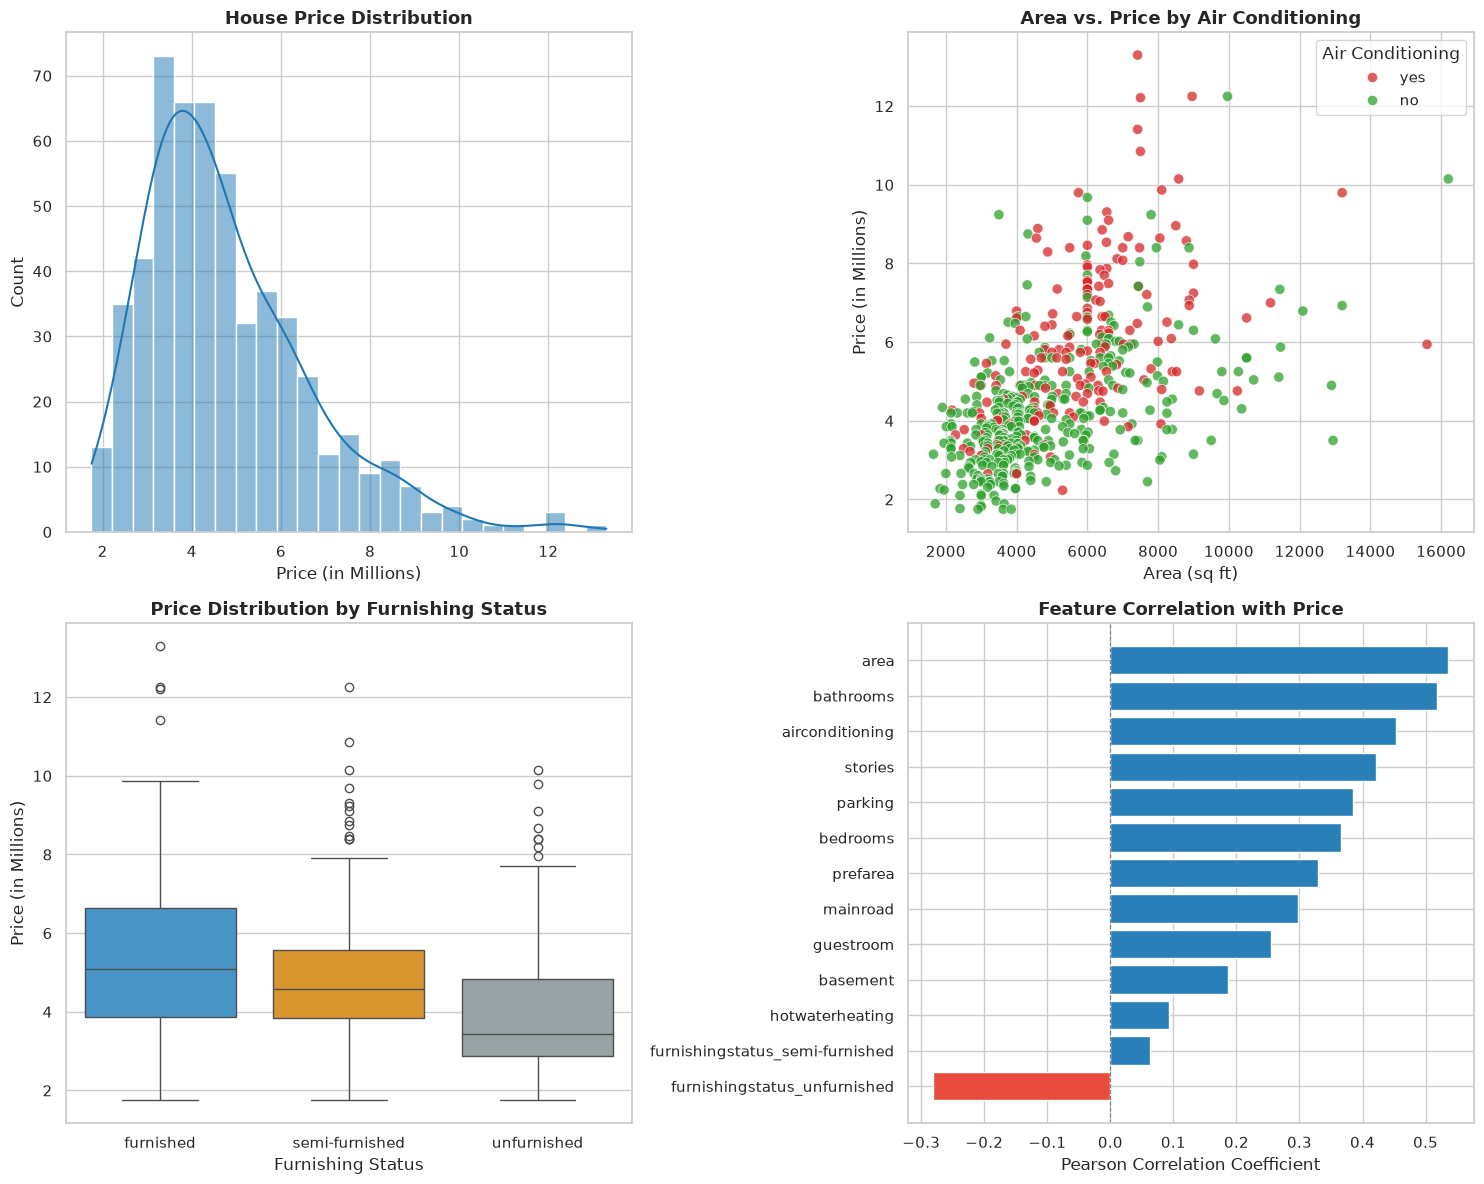

In [6]:
os.makedirs('figures', exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Price Distribution
sns.histplot(df['price'] / 1e6, kde=True, ax=axes[0, 0], color='#1f77b4', bins=25)
axes[0, 0].set_title('House Price Distribution', fontsize=13, fontweight='bold')
axes[0, 0].set_xlabel('Price (in Millions)')
axes[0, 0].set_ylabel('Count')

# 2. Area vs. Price colored by Air Conditioning
sns.scatterplot(
    data=df,
    x='area',
    y=df['price'] / 1e6,
    hue='airconditioning',
    palette={'yes': '#d62728', 'no': '#2ca02c'},
    alpha=0.75,
    s=55,
    ax=axes[0, 1]
)
axes[0, 1].set_title('Area vs. Price by Air Conditioning', fontsize=13, fontweight='bold')
axes[0, 1].set_xlabel('Area (sq ft)')
axes[0, 1].set_ylabel('Price (in Millions)')
axes[0, 1].legend(title='Air Conditioning')

# 3. Price by Furnishing Status
furnishing_order = ['furnished', 'semi-furnished', 'unfurnished']
sns.boxplot(
    data=df,
    x='furnishingstatus',
    y=df['price'] / 1e6,
    order=furnishing_order,
    palette=['#3498db', '#f39c12', '#95a5a6'],
    ax=axes[1, 0]
)
axes[1, 0].set_title('Price Distribution by Furnishing Status', fontsize=13, fontweight='bold')
axes[1, 0].set_xlabel('Furnishing Status')
axes[1, 0].set_ylabel('Price (in Millions)')

# 4. Feature Correlations with Price
correlations = df_clean.corr()['price'].drop('price').sort_values()
bar_colors = ['#e74c3c' if v < 0 else '#2980b9' for v in correlations]
axes[1, 1].barh(correlations.index, correlations.values, color=bar_colors)
axes[1, 1].axvline(0, color='gray', linestyle='--', linewidth=0.8)
axes[1, 1].set_title('Feature Correlation with Price', fontsize=13, fontweight='bold')
axes[1, 1].set_xlabel('Pearson Correlation Coefficient')

plt.tight_layout()
plt.savefig('figures/eda_summary.png', dpi=300, bbox_inches='tight')
plt.show()

Key takeaways from EDA:
- **Target Skewness**: House prices center around a median of 4.34M with a long right tail reaching 13.3M.
- **Area & Air Conditioning**: Living area demonstrates a strong positive linear correlation with house price (r = 0.536). Across all area sizes, homes equipped with air conditioning systematically sell at a premium compared to non-AC homes.
- **Furnishing Premium**: Furnished properties command the highest median price, followed by semi-furnished homes. Unfurnished homes show both lower median prices and lower upper bounds.
- **Correlation Ranking**: The strongest positive correlates with price are living area (0.536), bathrooms (0.518), air conditioning (0.453), and stories (0.424). Being unfurnished shows a distinct negative correlation (-0.281) relative to the baseline.

## 4. Model Creation

We train six diverse regression models to establish baselines and evaluate non-linear and target-transformed methods:
- **Linear Regression**: Classical Ordinary Least Squares (OLS) regressor.
- **Ridge Regression**: L2-penalized regression to prevent coefficient explosion.
- **Lasso Regression**: L1-penalized regression capable of feature selection.
- **Random Forest Regressor**: Bagging ensemble of 100 decision trees.
- **Gradient Boosting Regressor**: Boosting ensemble sequentially optimizing squared loss.
- **Log-Linear Regression**: Linear regression with log-transformed price via `TransformedTargetRegressor` to accommodate target skewness.

In [7]:
models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'Lasso': Lasso(alpha=100.0, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, random_state=42),
    'Log-Linear Regression': TransformedTargetRegressor(
        regressor=LinearRegression(),
        func=np.log1p,
        inverse_func=np.expm1
    )
}

trained_models = {}
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    print(f'Trained {name}')

Trained Linear Regression
Trained Ridge
Trained Lasso
Trained Random Forest
Trained Gradient Boosting
Trained Log-Linear Regression


All models are trained on the standardized training partition. We now proceed to out-of-sample evaluation and cross-validation.

## 5. Model Evaluation

We evaluate all trained models on the test set using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and Test R2 score. In addition, we compute 5-fold cross-validation R2 scores on the training set to check stability and protect against overfitting.

In [8]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
records = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_scaled)
    
    mae = mean_absolute_error(y_test, y_pred)
    rmse = root_mean_squared_error(y_test, y_pred)
    test_r2 = r2_score(y_test, y_pred)
    cv_r2 = cross_val_score(model, X_train_scaled, y_train, cv=kf, scoring='r2').mean()
    
    records.append({
        'Model': name,
        'MAE': mae,
        'RMSE': rmse,
        'Test R2': test_r2,
        '5-Fold CV R2': cv_r2
    })

comparison_df = pd.DataFrame(records)
comparison_df['MAE (Rs)'] = comparison_df['MAE'].apply(lambda x: f'{x:,.0f}')
comparison_df['RMSE (Rs)'] = comparison_df['RMSE'].apply(lambda x: f'{x:,.0f}')
comparison_df['Test R2'] = comparison_df['Test R2'].round(4)
comparison_df['5-Fold CV R2'] = comparison_df['5-Fold CV R2'].round(4)

display(comparison_df[['Model', 'MAE (Rs)', 'RMSE (Rs)', 'Test R2', '5-Fold CV R2']])

,Model,MAE (Rs),RMSE (Rs),Test R2,5-Fold CV R2
0,Linear Regression,"970,043","1,324,507",0.6529,0.6490
1,Ridge,"971,370","1,326,096",0.6521,0.6495
2,Lasso,"970,106","1,324,623",0.6529,0.6490
3,Random Forest,"1,022,197","1,400,694",0.6118,0.6070
4,Gradient Boosting,"960,579","1,299,761",0.6658,0.6074
5,Log-Linear Regression,"960,123","1,314,648",0.6581,0.6575


To inspect error distributions and model fit, we generate diagnostic Actual vs. Predicted and Residuals vs. Predicted plots for the top performing model on the test set (Gradient Boosting). The figure is saved to `figures/model_evaluation.png`.

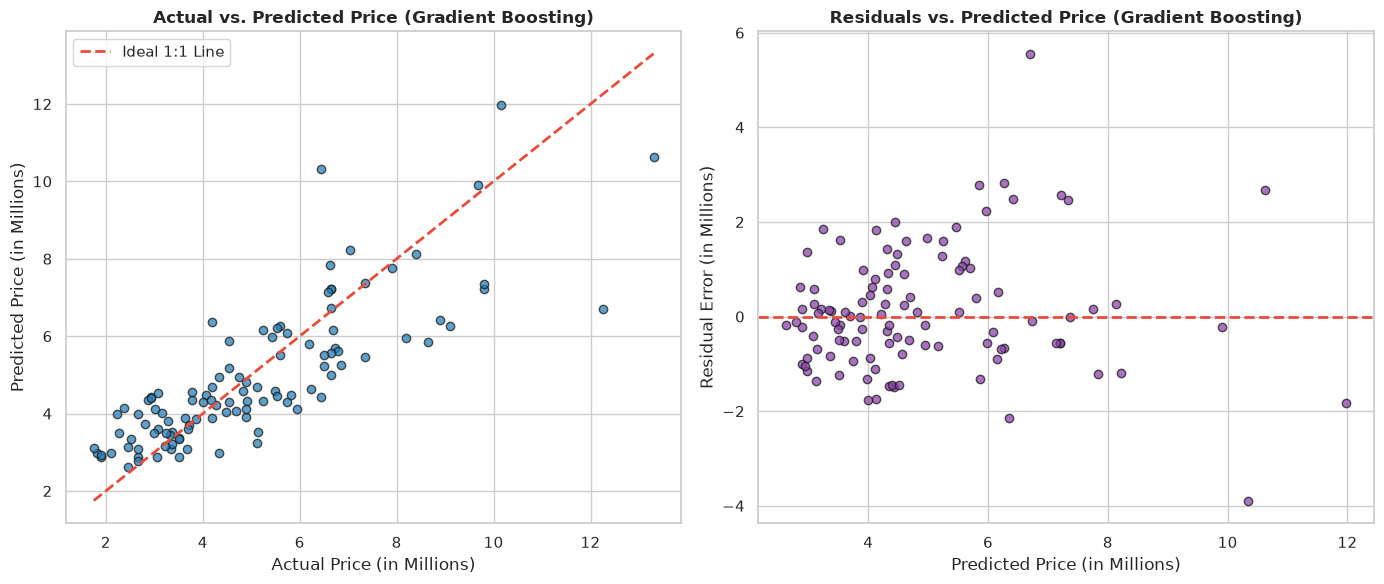

In [9]:
best_name = 'Gradient Boosting'
best_model = trained_models[best_name]
y_pred_best = best_model.predict(X_test_scaled)
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Actual vs Predicted
axes[0].scatter(y_test / 1e6, y_pred_best / 1e6, color='#2980b9', alpha=0.75, edgecolors='k')
min_p = min(y_test.min(), y_pred_best.min()) / 1e6
max_p = max(y_test.max(), y_pred_best.max()) / 1e6
axes[0].plot([min_p, max_p], [min_p, max_p], color='#e74c3c', linestyle='--', linewidth=2, label='Ideal 1:1 Line')
axes[0].set_title(f'Actual vs. Predicted Price ({best_name})', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Actual Price (in Millions)')
axes[0].set_ylabel('Predicted Price (in Millions)')
axes[0].legend()

# 2. Residuals vs Predicted
axes[1].scatter(y_pred_best / 1e6, residuals / 1e6, color='#8e44ad', alpha=0.75, edgecolors='k')
axes[1].axhline(0, color='#e74c3c', linestyle='--', linewidth=2)
axes[1].set_title(f'Residuals vs. Predicted Price ({best_name})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Price (in Millions)')
axes[1].set_ylabel('Residual Error (in Millions)')

plt.tight_layout()
plt.savefig('figures/model_evaluation.png', dpi=300, bbox_inches='tight')
plt.show()

We now examine the feature coefficients from the Linear Regression model to quantify the financial impact of each housing feature.

Model Intercept: Rs 3,969,403.56

Feature Coefficients (sorted):
airconditioning                     : Rs   791,426.74
hotwaterheating                     : Rs   684,649.89
prefarea                            : Rs   629,890.57
bathrooms                           : Rs   521,879.03
area                                : Rs   519,552.42
basement                            : Rs   390,251.18
mainroad                            : Rs   367,919.95
stories                             : Rs   349,251.44
guestroom                           : Rs   231,610.04
parking                             : Rs   192,005.95
bedrooms                            : Rs    57,349.56
furnishingstatus_semi-furnished     : Rs  -126,881.82
furnishingstatus_unfurnished        : Rs  -413,645.06


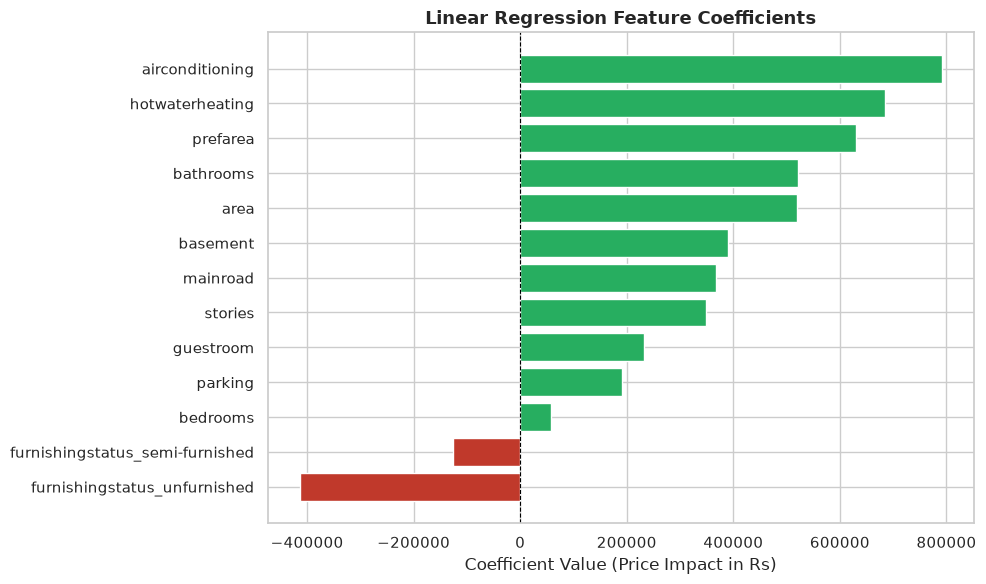

In [10]:
lr = trained_models['Linear Regression']
coef_df = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': lr.coef_
}).sort_values(by='Coefficient', ascending=False).reset_index(drop=True)

print(f'Model Intercept: Rs {lr.intercept_:,.2f}\n')
print('Feature Coefficients (sorted):')
for _, row in coef_df.iterrows():
    print(f"{row['Feature']:<35} : Rs {row['Coefficient']:>12,.2f}")

plt.figure(figsize=(10, 6))
bar_colors = ['#27ae60' if c > 0 else '#c0392b' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=bar_colors)
plt.axvline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Linear Regression Feature Coefficients', fontsize=13, fontweight='bold')
plt.xlabel('Coefficient Value (Price Impact in Rs)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Conclusion and Summary

1. **Model Performance**:
   - **Gradient Boosting** achieved the highest test set score with a Test R2 of **0.6658**, lowest MAE of **Rs 960,579**, and lowest RMSE of **Rs 1,299,761**.
   - **Log-Linear Regression** achieved the highest 5-Fold Cross-Validation R2 of **0.6575** and a strong test R2 of **0.6581**, demonstrating that normalizing the target price variable reduces variance and improves out-of-fold generalization.
   - Standard **Linear Regression**, **Ridge**, and **Lasso** produced virtually identical results (Test R2 ≈ 0.6529, CV R2 ≈ 0.6490), confirming that multicollinearity is modest and strong linear relationships govern this dataset.
   - **Random Forest** achieved a Test R2 of 0.6118, lagging slightly behind the linear and gradient boosting models on this sample size.

2. **Key Price Drivers**:
   - **Air conditioning** is the most valuable binary amenity, adding approximately Rs 791,427 to house value.
   - **Hot water heating** (+Rs 684,650) and **preferred area location** (+Rs 629,891) follow closely as major pricing factors.
   - **Bathrooms** (+Rs 521,879 per standard deviation) and **living area** (+Rs 519,552 per standard deviation) are the primary physical dimension drivers.
   - **Unfurnished status** introduces a substantial penalty of ~Rs 413,645 relative to fully furnished homes.

3. **Practical Implications**:
   - For automated valuation systems, Gradient Boosting provides optimal precision, while Linear Regression provides clear explainability and transparency for clients and home appraisers.